---
tags:
  - sparse-ad
  - nonlinear
  - viscoelastic
---

# Standard Linear Solid Model

!!! info

    This example uses `soldis` solver to solve the nonlinear problem. You can install it via `pip install git+https://github.com/smec-ethz/soldis.git`.


In [ ]:
# Only run this if we are in Google Colab
if "google.colab" in str(get_ipython()):
    print("Installing dependencies using uv...")
    # Install uv if not available
    !pip install -q uv
    # Install system dependencies
    !apt-get install -qq gmsh
    # Use uv to install Python dependencies
    !uv pip install --system matplotlib meshio
    !uv pip install --system "git+https://github.com/smec-ethz/tatva-docs.git"
    !uv pip install --system "git+https://github.com/smec-ethz/soldis.git"
    print("Installation complete!")

We solve a 2D **viscoelastic stress relaxation** problem on a rectangular plate ($0.1 \times 0.2\;\text{m}$) under **plane stress** conditions using the **Standard Linear Solid (Zener) model**. Symmetry boundary conditions are imposed on the left ($u_x = 0$) and bottom ($u_y = 0$) edges, while a constant tensile prestrain $\overline{\varepsilon} = 10^{-3}$ is applied instantaneously to the top edge ($u_y = \overline{\varepsilon} H$) and held fixed over time ($t \in [0, 0.5]\;\text{s}$). As the dashpot relaxes with characteristic time $\tau_1 = \eta_1 / E_1$, the viscous strain $\varepsilon_{yy}^v(t)$ grows toward $\overline{\varepsilon}$ and the axial stress $\sigma_{yy}(t)$ decays exponentially from $(E_0 + E_1)\overline{\varepsilon}$ to the equilibrium value $E_0 \overline{\varepsilon}$, which is validated against the analytical solution.

**How `tatva` + `soldis` simplify this:**

- `Mesh` + `Operator`: discrete geometry, gradients ($\nabla u$), and quadrature integration ($\int_V \cdot\,dV$).
- `Compound` + `Lifter`: typed nodal fields and automatic separation of free vs. Dirichlet DOFs.
- `jax.grad` + `tatva.sparse`: residual and colored sparse tangent stiffness directly from $\Pi(u)$, with no manual element assembly.
- `soldis`: JIT-compiled sparse Newton solver in pure JAX.

# Libraries

In [1]:
from typing import NamedTuple

import jax

jax.config.update("jax_enable_x64", True)
jax.config.update("jax_platforms", "cpu")

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from jax import Array
from jax_autovmap import autovmap
from soldis.linear import SparseTatva
from soldis.newton import LineSearchNewtonSolver, LineSearchNewtonSolverOptions

from tatva import Mesh, Operator, compound, element, lifter, linalg, sparse

# Parameters

- **Geometry (`g_p`)**: Plate dimensions (`width`, `height` in m) and structured grid resolution (`Nx`, `Ny`).
- **Material (`m_p`)**: Equilibrium Young's modulus `E_0` (MPa), Poisson's ratio `nu`, Maxwell dashpot viscosity `eta_1` ($\text{MPa}\cdot\text{s}$), and relaxation time `tau_1` (s), which defines the Maxwell spring modulus $E_1 = \eta_1 / \tau_1$.
- **Time & Loading**: Step size `dt`, total duration `total_time`, and imposed constant prestrain `prestrain` ($u_y = \text{prestrain} \times \text{height}$).

In [2]:
g_p = {
    "width": 0.1,
    "height": 0.2,
    "Nx": 50,
    "Ny": 50,
}

m_p = {
    "E_0": 70e3,
    "nu": 0.3,
    "eta_1": 1e3,
    "tau_1": 0.05,
    "plane_stress": True,  # False for plane strain
}


# dt          = 5e-2
dt = 0.5e-2  # changed this to create more time steps
total_time = 0.5
Nincr = int(total_time / dt) + 1
time_domain = jnp.linspace(0, total_time, Nincr)

prestrain = 1e-3
total_disp = prestrain * g_p["height"]
delta_disp = total_disp / Nincr

# Mesh

`gen_mesh` builds a structured 2D rectangular grid of $(N_x + 1) \times (N_y + 1)$ nodes (`coords` of shape `(n_nodes, 2)`) and splits each cell into two counter-clockwise `Tri3` triangles (`elements` of shape `(2 * Nx * Ny, 3)`). Wrapping them in `tatva.Mesh(coords, elements=elements)` stores the coordinates and connectivity as JAX arrays for `Operator` and `Compound`.

In [3]:
def gen_mesh(width: float, height: float, Nx: int, Ny: int):
    x = np.linspace(0.0, width, Nx + 1)
    y = np.linspace(0.0, height, Ny + 1)
    xv, yv = np.meshgrid(x, y, indexing="ij")
    coords = np.column_stack([xv.ravel(), yv.ravel()])

    i = np.arange(Nx)[:, None]
    j = np.arange(Ny)[None, :]
    n00 = (i * (Ny + 1) + j).ravel()
    n10 = ((i + 1) * (Ny + 1) + j).ravel()
    n01 = (i * (Ny + 1) + (j + 1)).ravel()
    n11 = ((i + 1) * (Ny + 1) + (j + 1)).ravel()

    tris_1 = np.column_stack([n00, n10, n11])
    tris_2 = np.column_stack([n00, n11, n01])
    elements = np.vstack([tris_1, tris_2])
    return coords, elements

In [4]:
coords, elements = gen_mesh(g_p["width"], g_p["height"], g_p["Nx"], g_p["Ny"])

mesh = Mesh(coords, elements=elements)

nb_dofs = 2 * coords.shape[0]
nb_dofs_per_node = coords.shape[1]

gdim = coords.shape[1]
n_elems = mesh.elements.shape[0]

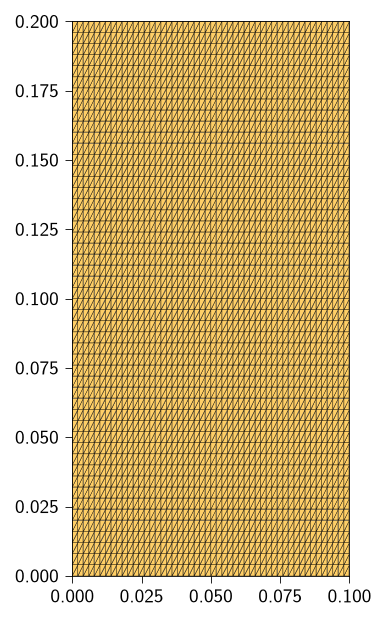

In [5]:
fig, ax = plt.subplots(1, 1)

ax.tripcolor(
    mesh.coords[:, 0],
    mesh.coords[:, 1],
    mesh.elements,
    facecolors=np.ones(len(mesh.elements)),
    cmap="managua",
    edgecolors="k",
    linewidth=0.2,
)


ax.margins(0, 0)
ax.set_aspect("equal")
plt.show()

# Operator & Solution Field

- `Operator(mesh, element.Tri3())` provides finite-element spatial derivatives (`op.grad`) and quadrature integration (`op.integrate`) on linear triangular elements.
- `Compound` defines the nodal displacement field $u = (u_x, u_y)$ and maps slice indexing like `Solution.u[nodes, comp]` to global DOF indices.

In [6]:
op = Operator(mesh, element.Tri3())  # This is used for the integrals
nb_quads_per_element = len(op.element.quad_points)
nb_qdpts = nb_quads_per_element * n_elems

In [7]:
class Solution(compound.Compound, mesh=mesh):
    u = compound.field(
        shape=(compound.FieldSize.AUTO, gdim),
        field_type=compound.FieldType.NODAL,
    )

# Boundary conditions

`Lifter` separates the unknown **free DOFs** from constrained **Dirichlet DOFs** and reconstructs the full displacement vector via `lift_from_zeros(u_free)`:

- Symmetry condition on left and bottom edges ($u_x = 0$ on left, $u_y = 0$ on bottom)
- Imposed constant prestrain $u_y = \text{total\_disp}$ on top edge

In [8]:
# Identify boundaries
y_max = jnp.max(mesh.coords[:, 1])
y_min = jnp.min(mesh.coords[:, 1])
x_min = jnp.min(mesh.coords[:, 0])
x_max = jnp.max(mesh.coords[:, 0])

# Nodes that will be used to apply boundary conditions
top_nodes = jnp.where(jnp.isclose(mesh.coords[:, 1], y_max))[0]
bottom_nodes = jnp.where(jnp.isclose(mesh.coords[:, 1], y_min))[0]
left_nodes = jnp.where(jnp.isclose(mesh.coords[:, 0], x_min))[0]

In [9]:
lifter_ = lifter.Lifter(
    Solution.size,
    lifter.Fixed(Solution.u[left_nodes, 0], 0.0),  # ux=0 on Left
    lifter.Fixed(Solution.u[bottom_nodes, 1], 0.0),  # uy=0 on Bottom
    lifter.Fixed(Solution.u[top_nodes, 1], total_disp),  # Applied prestrain on Top
)

# Material

For an isotropic linear elastic material under small deformations, the Cauchy stress and Helmholtz free-energy density are written directly in terms of the Lamé parameters $(\lambda, \mu)$ and the strain tensor $\varepsilon = \frac{1}{2}\left(\nabla u + {\nabla u}^T\right)$:
\begin{equation}
\sigma = 2\mu\varepsilon + \lambda\,\text{tr}(\varepsilon)\,\mathbf{I}\;, \qquad \Psi_e(\varepsilon) = \mu(\varepsilon : \varepsilon) + \frac{1}{2}\lambda\,\text{tr}(\varepsilon)^2\;.
\tag{1}
\end{equation}

To model viscoelasticity, we use the _standard linear solid_ (or Zener) model, whose total free-energy density sums the equilibrium branch $\Psi_e^{(0)}(\varepsilon)$ and the Maxwell spring branch $\Psi_{ve}^{(1)}(\varepsilon_e^{(1)})$:

```text
        ┌─────────[ E_0 ]─────────┐
── ε ───┤                         ├─── σ
        └──[ E_1 ]──┤├─[ η_1 ]────┘
```

The standard solid model is a rheological one-dimensional model that combines one spring in parallel with a Maxwell element (dashpot + spring in series), such that the first branch (spring alone) represent the pure elastic response of the material (standard linear elasticity) and the second branch (Maxwell element) represents the viscoelastic response. The spring on the first branch has a Young's modulus $E^{(0)}$ and associated strain $\varepsilon_e^{(0)}$, the spring on the second branch has Young's modulus $E_1$ and an elastic deformation $\varepsilon_e^{(1)}$, and the dashpot has a viscosity $\eta^{(1)}$ and viscous strain $\varepsilon_v^{(1)}$.

Since in the Maxwell element the dashpot and spring are in series, the combined viscoelastic strain for the second branch is:

\begin{equation}
\varepsilon_{ve}^{(1)} = \varepsilon_v^{(1)} + \varepsilon_e^{(1)}
\tag{2}
\end{equation}

Then, if we apply a total deformation $\varepsilon$ to the system, since the branches are in parallel, this $\varepsilon$ will be the same on both branches, such that:
\begin{equation}
\varepsilon = \varepsilon_e^{(0)}  = \varepsilon_{ve}^{(1)}
\tag{3}
\end{equation}


On the other hand, the applied total strain $\varepsilon$ is related with a total stress $\sigma$. In the case of stresses, parallel will mean summation and series will mean equality. Then, the applied stress $\sigma$ is distributed on both branches:
\begin{equation}
\sigma = \sigma^{(0)}_e + \sigma^{(1)}_{ve}\;.
\tag{4}
\end{equation}
The first term is the reversible contribution (pure elastic) and the second term is the irreversible contribution to the total stress. Now, using the Hooke's law $\sigma=E\varepsilon$, we can express the stresses in terms of strains. We will use the spring of the Maxwell element to model the viscoelastic stress as a function of the viscous strain $\varepsilon_v^{(1)}$, because the spring is the only element which is capable to store elastic energy (dasht can't). So from Eq. $(2)$ we can do $\varepsilon_e^{(1)} = \varepsilon_v^{(1)}-\varepsilon_{ve}^{(1)}$, and considering condition defined in Eq. $(3)$, we have that $\varepsilon_e^{(1)} = \varepsilon_v^{(1)}-\varepsilon_{e}^{(0)}$. Note also that in the Maxwell element the spring is couple with the dashpot, so that we can compute:
\begin{equation}
E^{(1)} = \frac{\eta^{(1)}}{\tau^{(1)}}\;,
\tag{5}
\end{equation}
where $\tau^{(1)}$ is the relaxation time associated with the Maxwell element. Furthermore, the representative viscoelastic stress associated with the spring of stiffness $E^{(1)}$ is $\sigma_{ve}^{(1)}=E^{(1)}\varepsilon_{e}^{(1)}=E^{(1)} \left(\varepsilon_v^{(1)}-\varepsilon_{e}^{(0)}\right)$. Furthermore, the stress on the first branch is pure elastic, so $\sigma^{(0)}_e=E^{(0)}\varepsilon_e^{(0)}$, but since $\varepsilon = \varepsilon_e^{(0)}$, we have that $\sigma^{(0)}_e=E^{(0)}\varepsilon$. Finally:
\begin{equation}
\sigma = E^{(0)}\varepsilon + E^{(1)}(\varepsilon-\varepsilon^v)
\tag{6}
\end{equation}

Now, from the solver we can get the value of $\varepsilon$ but we still need to find $\varepsilon_v^{(1)}$. For this purpose, we need to define a second equation for the new variable (which is normally called an _internal variable_, because it is not part of the main equilibrium equation). Among other options, we will use the _evolution equation_ for the internal variable $\varepsilon_v^{(1)}$:

\begin{equation}
\dot{\varepsilon}_v^{(1)} = \dfrac{E^{(1)}}{\eta^{(1)}}(\varepsilon-\varepsilon_v^{(1)}) \;.
\tag{7}
\end{equation}
This is an evolution equation because it models changes of $\varepsilon_v^{(1)}$ in time, that is why we have a $\dot{\varepsilon}_v^{(1)}$, which denotes derivative with respect time. We can also express it in terms of the viscoelastic stress:

\begin{equation}
\dot{\sigma}^\text{v} + \dfrac{1}{\tau}\sigma_v^{(1)} = E^{(1)}\dot{\varepsilon}
\tag{8}
\end{equation}

Time integration:

\begin{equation}
\sigma_{ve}^{(1)}(t_{n+1}) = e^{-\Delta t/\tau}\sigma_v^{(1)}(t_n) + E^{(1)}\int_{t_n}^{t_{n+1}}e^{-(t_{n+1}-t)/\tau}\dot\varepsilon(t)\, \text{d}t
\tag{9}
\end{equation}

We will use a semi-analytical solution for the integral, which results in:

\begin{equation}
\sigma_{ve}^{(1)}(t_{n+1}) = e^{-\Delta t/\tau}\sigma_{ve}^{(1)}(t_n) + E^{(1)} e^{-\Delta t/(2\tau)}\Delta\varepsilon
\tag{10}
\end{equation}

And in terms of strain:

\begin{equation}
{}^{n+1}\varepsilon_v = {}^{n+1}\varepsilon +e^{-\Delta t/\tau}({}^{n}\varepsilon_v^{(1)}-{}^{n}\varepsilon) - e^{-\Delta t/(2\tau)}({}^{n+1}\varepsilon-{}^{n}\varepsilon)
\tag{11}
\end{equation}

\begin{equation}
\therefore {}^{n+1}\varepsilon - {}^{n+1}\varepsilon_v = e^{-\Delta t/(2\tau)} \Delta \varepsilon - e^{-\Delta t/\tau}({}^{n}\varepsilon_v^{(1)}-{}^{n}\varepsilon)
\tag{12}
\end{equation}

In [10]:
class Material(NamedTuple):
    """
    Material properties for the elasticity-viscoelasticity operator.
    """

    mu: float  # Shear modulus (equilibrium)
    lmbda: float  # Lamé's first parameter (equilibrium)
    mu_1: float  # Shear modulus (Maxwell branch)
    lmbda_1: float  # Lamé's parameter (Maxwell branch)
    eta_1: float  # Viscosity (Maxwell)
    tau_1: float  # Relaxation time (Maxwell)
    E_1: float  # Young modulus (Maxwell, derived)
    E_0: float  # Young modulus (equilibrium/spring 0)

    @classmethod
    def from_youngs_poisson_2d(
        cls,
        E_0: float,
        nu: float,
        eta_1: float,
        tau_1: float,
        plane_stress: bool = False,
    ) -> "Material":
        """
        Convert material parameters from engineering constants.

        Args:
            E_0 (float): Young's modulus (equilibrium/spring 0)
            nu (float): Poisson's ratio
            eta_1 (float): Viscosity (Maxwell branch)
            tau_1 (float): Relaxation time (Maxwell branch)
            plane_stress (bool): Use plane stress (default False: plane strain)

        Returns:
            Material: Constructed material with all parameters filled
        """
        E_1 = eta_1 / tau_1

        mu_0 = E_0 / (2 * (1 + nu))
        mu_1 = E_1 / (2 * (1 + nu))

        if plane_stress:
            # Plane stress formulas
            lmbda_0 = 2 * nu * mu_0 / (1 - nu)
            lmbda_1 = 2 * nu * mu_1 / (1 - nu)
        else:
            # Plane strain formulas
            lmbda_0 = E_0 * nu / ((1 + nu) * (1 - 2 * nu))
            lmbda_1 = E_1 * nu / ((1 + nu) * (1 - 2 * nu))

        return cls(
            mu=mu_0,
            lmbda=lmbda_0,
            mu_1=mu_1,
            lmbda_1=lmbda_1,
            eta_1=eta_1,
            tau_1=tau_1,
            E_1=E_1,
            E_0=E_0,
        )


mat = Material.from_youngs_poisson_2d(
    m_p["E_0"], m_p["nu"], m_p["eta_1"], m_p["tau_1"], m_p["plane_stress"]
)

In [11]:
@autovmap(grad_u=2)
def compute_strain(grad_u):
    return 0.5 * (grad_u + grad_u.T)


@autovmap(eps=2, lmbda=0, mu=0)
def compute_stress(eps, lmbda, mu):
    return 2 * mu * eps + lmbda * jnp.trace(eps) * jnp.eye(2)


@autovmap(eps=2, eps0=2, epsv0=2, dt=0)
def compute_viscoelastic_strain(eps, eps0, epsv0, dt):
    # Strain increment
    deps = eps - eps0

    # Semi-analytical solution for the viscous strain
    epsv = (
        eps
        + jnp.exp(-dt / mat.tau_1) * (epsv0 - eps0)
        - jnp.exp(-dt / 2 / mat.tau_1) * deps
    )

    # Viscoelastic strain
    eps_e_1 = eps - epsv

    return eps_e_1, epsv


@autovmap(eps=2, eps_e_1=2)
def strain_energy_density(eps: Array, eps_e_1: Array) -> Array:
    tr_eps = jnp.trace(eps)
    tr_eps_e_1 = jnp.trace(eps_e_1)

    ed_e0 = (
        mat.mu * linalg.einsum("ij,ij->", eps, eps) + 0.5 * mat.lmbda * tr_eps * tr_eps
    )
    ed_ve1 = (
        mat.mu_1 * linalg.einsum("ij,ij->", eps_e_1, eps_e_1)
        + 0.5 * mat.lmbda_1 * tr_eps_e_1 * tr_eps_e_1
    )

    return ed_e0 + ed_ve1

# Potential Energy & Global AD

In `tatva`, we only need to formulate the scalar potential energy functional:

$$\Pi(u) = \int_V \left(\Psi^e + \Psi^{ve}\right)\text{d}V$$

Using **global automatic differentiation** directly on $\Pi(u)$, we obtain the internal force vector $f_\text{int} = \frac{\partial \Pi}{\partial u}$ (`jax.grad`) and, in the solver section, the tangent stiffness matrix $K = \frac{\partial r}{\partial u} = -\frac{\partial^2 \Pi}{\partial u^2}$ (`sparse.jacfwd`). This mirrors the exact variational/mathematical formulation without manually deriving or assembling element vectors and stiffness matrices.

In [12]:
def internal_potential_energy(
    u_full: Array, eps0: Array, epsv0: Array, dt: float
) -> Array:
    # Compute strain tensor
    u = u_full.reshape(-1, 2)
    grad_u = op.grad(u)
    eps = compute_strain(grad_u)

    # Compute viscoelastic strain
    eps_e_1, _ = compute_viscoelastic_strain(eps, eps0, epsv0, dt)

    # Compute total strain energy density
    energy_density = strain_energy_density(eps, eps_e_1)

    # Return total strain energy
    return op.integrate(energy_density)


@jax.jit
def total_energy_free(
    u_free: Array, lifter_obj: lifter.Lifter, eps0: Array, epsv0: Array, dt: float
) -> Array:
    u_full = Solution(lifter_obj.lift_from_zeros(u_free)).u
    return internal_potential_energy(u_full, eps0, epsv0, dt)

Gradient of the potential energy (total energy) which is actually the internal force:

$$\frac{\partial \Pi}{\partial u}=f_\text{int}$$

In [13]:
compute_internal_free = jax.grad(total_energy_free, argnums=0)

# Solver

We will use `soldis`'s sparse Newton solver. The advantage of the sparse solver is that we only solve a system consisting of the DOFs with unknown displacement values. Thus, we don't include in the solving process the DOFs with imposed values, e.g., the DOFs related with the boundary conditions and the applied stretch (we already know their values).

In [16]:
@jax.jit
def fn(
    u: Array,
    lifter_obj: lifter.Lifter,
    fext: Array,
    eps0: Array,
    epsv0: Array,
    dt: float,
) -> Array:
    fint = compute_internal_free(u, lifter_obj, eps0, epsv0, dt)
    return fext - fint

`sparse.pattern_from_energy` traces `total_energy_free` to extract the reduced Jacobian sparsity pattern, `ColoredMatrix` + `sparse.jacfwd` computes the sparse tangent stiffness $K = \partial r/\partial u_\text{free}$ via graph coloring, and `LineSearchNewtonSolver` + `SparseTatva()` solves the system (compiled once with `jax.jit`).

In [17]:
eps0_dummy = jnp.zeros((n_elems, nb_quads_per_element, gdim, gdim))
epsv0_dummy = jnp.zeros((n_elems, nb_quads_per_element, gdim, gdim))
dt_dummy = jnp.float64(dt)

nb_free_dofs = lifter_.size_reduced

sparsity_pattern = sparse.pattern_from_energy(
    total_energy_free, nb_free_dofs, lifter_, eps0_dummy, epsv0_dummy, dt_dummy
)

In [18]:
colored_mat = sparse.ColoredMatrix.from_csr(sparsity_pattern)

hessian_fn = sparse.jacfwd(
    fn=fn,
    colored_matrix=colored_mat,
    color_batch_size=int(colored_mat.colors.max() + 1),
)
hessian_fn = jax.jit(hessian_fn)

In [19]:
solver_options = LineSearchNewtonSolverOptions(
    tol=1e-10,
    maxiter=200,
    verbose=True,
)

solver = LineSearchNewtonSolver(
    fn,
    lin_solver=SparseTatva(),
    jac=hessian_fn,
    options=solver_options,
)
solve_step = jax.jit(solver.root)

# Run simulation

At each time step, `solve_step` solves for $u_{n+1}$ while differentiating $\varepsilon_e^{(1)}(u; \varepsilon_n, \varepsilon_{v,n})$ consistently with respect to $u$. Once converged, the updated $\varepsilon_{n+1}$ and $\varepsilon_{v,n+1}$ are stored as the history state (`eps0`, `epsv0_1`) for the next $\Delta t$.

Initialize variables:

In [20]:
# Define tensor (n_elems, n_qpts_per_elem, gdim, gdim)
eps0 = jnp.zeros((n_elems, 1, gdim, gdim))
epsv0_1 = jnp.zeros((n_elems, 1, gdim, gdim))

# Define reduced vectors:
u_free = jnp.zeros(nb_free_dofs)
fext_free = jnp.zeros(nb_free_dofs)

# Define storage lists
disp_vals = []
eps_vals = []
epse_1_vals = []
epsv_1_vals = []

Run

In [25]:
for i, time_i in enumerate(time_domain):
    if i % 20 == 0:
        print(f"Step {i + 1}/{Nincr} (Time: {time_i:.5f}/{total_time:.5f})")

    # Update history variables
    if i > 0:
        eps0 = eps
        epsv0_1 = epsv_1


    # Solve for u
    state = solve_step(u_free, lifter_, fext_free, eps0, epsv0_1, dt)
    u_free = state.value

    # Check convergence
    
    assert bool(state.converged), (
        f"   Step {i + 1} FAILED after {int(state.iteration)} iterations"
    )

    # Re-construct full displacement field
    u = Solution(lifter_.lift_from_zeros(u_free)).u

    # Update current variables
    grad_u = op.grad(u.reshape(-1, 2))
    eps = compute_strain(grad_u)
    epse_1, epsv_1 = compute_viscoelastic_strain(eps, eps0, epsv0_1, dt)

    # Store info
    disp_vals.append(u)
    eps_vals.append(eps.squeeze())
    epse_1_vals.append(epse_1.squeeze())
    epsv_1_vals.append(epsv_1.squeeze())

Step 1/101 (Time: 0.00000/0.50000)
Step 21/101 (Time: 0.10000/0.50000)
Step 41/101 (Time: 0.20000/0.50000)
Step 61/101 (Time: 0.30000/0.50000)
Step 81/101 (Time: 0.40000/0.50000)
Step 101/101 (Time: 0.50000/0.50000)


# Postprocessing

In [22]:
stress_e_vals = []
stress_ve_vals = []
avg_vstrain_yy = []
avg_stress_yy = []

for i in range(Nincr):
    u_i = disp_vals[i].reshape(-1, nb_dofs_per_node)

    sigma_e0 = compute_stress(eps_vals[i], mat.lmbda, mat.mu)
    sigma_ve_1 = compute_stress(epse_1_vals[i], mat.lmbda_1, mat.mu_1)
    sigma_i = sigma_e0 + sigma_ve_1

    stress_e_vals.append(sigma_e0)
    stress_ve_vals.append(sigma_ve_1)

    avg_vstrain_yy.append(jnp.mean(epsv_1_vals[i][:, 1, 1]))
    avg_stress_yy.append(jnp.mean(sigma_i.squeeze()[:, 1, 1]))

# Validation

Anaytical solutions:
$$
\varepsilon^v_{yy}(t) = \overline{\varepsilon}(1- \exp(-t/\tau_1))
$$
$$
\sigma_{yy}(t) = E_0\overline{\varepsilon} + E_1\overline{\varepsilon} \exp(-t/\tau_1)\;,
$$
where $\overline{\varepsilon}$ is the applied prestrain.

Source: https://link.springer.com/article/10.1007/s11043-010-9108-7

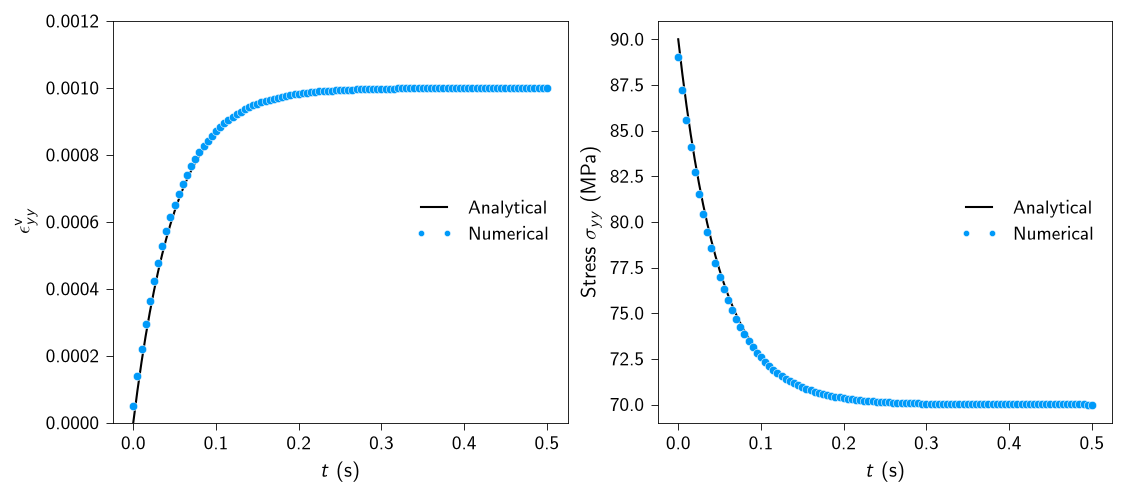

In [24]:
m_every = 1  # show markers every "m_every" points

fig, axs = plt.subplots(1, 2, figsize=(7.4, 3.2), layout="constrained")

sol_vstrain_yy = prestrain * (1 - np.exp(-time_domain / mat.tau_1))

axs[0].plot(
    time_domain, sol_vstrain_yy, marker="", ls="-", color="k", label="Analytical"
)
axs[0].plot(
    time_domain,
    avg_vstrain_yy,
    marker="o",
    markevery=m_every,
    ls="",
    label="Numerical",
)

axs[0].set_xlabel("$t$ (s)")
axs[0].set_ylabel(r"$\epsilon_{yy}^\mathrm{v}$")
axs[0].set_ylim(0, 1.2 * prestrain)
axs[0].legend(loc="center right", frameon=False)

sol_sig_yy = mat.E_0 * prestrain + mat.E_1 * prestrain * np.exp(
    -time_domain / mat.tau_1
)

axs[1].plot(time_domain, sol_sig_yy, marker="", ls="-", color="k", label="Analytical")
axs[1].plot(
    time_domain,
    avg_stress_yy,
    marker="o",
    markevery=m_every,
    ls="",
    label="Numerical",
)

axs[1].set_xlabel("$t$ (s)")
axs[1].set_ylabel(r"Stress $\sigma_{yy}$ (MPa)")
axs[1].legend(loc="center right", frameon=False)
plt.show()